In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [74]:
df = pd.read_csv('C:\\Users\\aadarsh kumar verma\\Data science\\mental_health_score_predictor\\data\\processed\\cleaned_data.csv')

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [76]:
x = x.drop(columns=['Unnamed: 0'])

In [77]:
numeric_cols = x.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

categorical_cols = x.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']

Categorical columns:
['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Stress_Level']


In [78]:
TARGET = "Mental_Health_Score"
x = df.drop(columns=[TARGET])
y = df[TARGET]


In [79]:
x_train ,x_test , y_train , y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42
)

In [80]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [81]:
# evaluate_model

def evaluate_model(model,x , y):
    pred = model.predict(x);
    mae = mean_absolute_error(y,pred)
    rmse = np.sqrt(mean_squared_error(y,pred))
    r2  = r2_score(y,pred)
    
    return mae , rmse , r2

In [82]:
#create model

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting":GradientBoostingRegressor(
        random_state=42
    ),
    "Hist Gradient Boosting":
        HistGradientBoostingRegressor(
            
            random_state=42
        )
}

In [83]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_Processed = preprocessor.transform(x_test)

In [84]:
#train models
results = []
train_models = {}

for name , estimator in models.items():
    print(f"\n Training { name} ...")
    
    pipeline = Pipeline([
        ("preprocessor" , preprocessor),
        ("model" , estimator)
    ])
    
    pipeline.fit(x_train,y_train)
    
    mae , rmse , r2 = evaluate_model(
        pipeline,
        x_test,
        y_test
    )
    
    results.append({
        "Model":name,
        "MAE":mae,
        "RMSE":rmse,
        "r2":r2
    })
    train_models[name]= Pipeline
    
    print("MAE",mae)
    print("RMSE",rmse)
    print("r2",r2)


 Training Linear Regression ...
MAE 0.47522222759388383
RMSE 0.61349452302601
r2 0.7891699476755072

 Training Ridge Regression ...
MAE 0.475788139285675
RMSE 0.6128559109641658
r2 0.7896086428354006

 Training Random Forest ...
MAE 0.27425619444444443
RMSE 0.38186637420025077
r2 0.9183165688953349

 Training Gradient Boosting ...
MAE 0.4114395157523057
RMSE 0.5311906876408883
r2 0.841943615899448

 Training Hist Gradient Boosting ...
MAE 0.34213962326026753
RMSE 0.4457367393787606
r2 0.8887069613035999


In [85]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

In [86]:
results_df

,Model,MAE,RMSE,r2
2,Random Forest,0.274256,0.381866,0.918317
4,Hist Gradient Boosting,0.342140,0.445737,0.888707
3,Gradient Boosting,0.411440,0.531191,0.841944
1,Ridge Regression,0.475788,0.612856,0.789609
0,Linear Regression,0.475222,0.613495,0.789170


In [87]:
best_model_name = results_df.iloc[0]["Model"]

best_estimator = models[best_model_name]

best_pipeline = Pipeline([
    ("preprocessor" , preprocessor),
    ("model" , best_estimator)
])

cv_results = cross_validate(
    best_pipeline,
    x_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

cv_results

{'fit_time': array([9.01250744, 8.83706641, 9.61333466, 8.89065957, 9.037925  ]),
 'score_time': array([0.53729224, 0.57688022, 0.16675735, 0.57998109, 0.54656172]),
 'test_MAE': array([-0.29039342, -0.29195792, -0.29181677, -0.29173536, -0.30483239]),
 'test_RMSE': array([-0.3914061 , -0.39171346, -0.41382662, -0.40202361, -0.42404172]),
 'test_R2': array([0.90795521, 0.90278173, 0.8870595 , 0.89689267, 0.88990953])}

In [88]:
print("Cross Validation Results")

print(
    "Mean MAE:",
    -cv_results["test_MAE"].mean()
)

print(
    "Mean RMSE:",
    -cv_results["test_RMSE"].mean()
)

print(
    "Mean R2:",
    cv_results["test_R2"].mean()
)

Cross Validation Results
Mean MAE: 0.2941471711045053
Mean RMSE: 0.40460230288836463
Mean R2: 0.8969197278917139


In [96]:
#hyperparameter tuning
rf_pipeline = Pipeline([
    ("preprocessor" , preprocessor),
    ("model" , RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 7],
    "model__min_samples_leaf": [1, 2]
}
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv = 5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train,y_train)

Fitting 5 folds for each of 54 candidates, totalling 270 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [98]:
best_model = grid_search.best_estimator_

print(grid_search.best_params_)

print(grid_search.best_score_)

{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
-0.40460230288836474


In [99]:
y_pred = best_model.predict(x_test)
mae = mean_absolute_error(y_test , y_pred)
rmse = np.sqrt(mean_squared_error(y_test , y_pred))
r2 = r2_score(y_test , y_pred)

print("MAE" , mae)
print("RMSE" , rmse)
print("R2" ,  r2)

MAE 0.27425619444444443
RMSE 0.38186637420025077
R2 0.9183165688953349


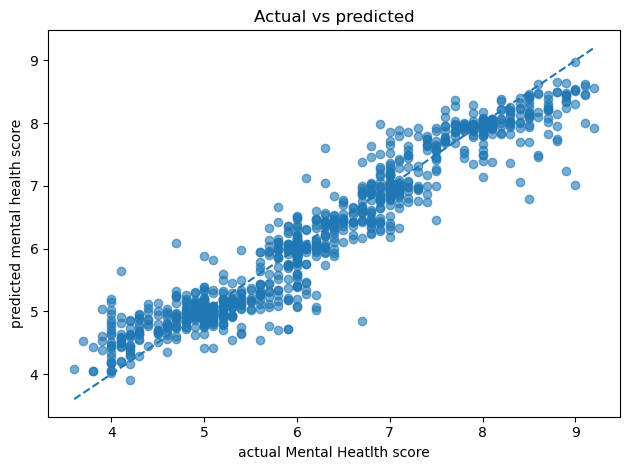

In [101]:
#actual vs predicated

plt.Figure(figsize=(7,7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)
min_value = min(
    y_test.min(),
    y_pred.min()
)
max_value = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [min_value , max_value],
    [min_value , max_value],
    linestyle="--"
)

plt.xlabel("actual Mental Heatlth score")
plt.ylabel("predicted mental health score")

plt.title("Actual vs predicted")

plt.tight_layout()

plt.show()

In [102]:
error_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
})

error_df["Error"] = (
    error_df["Actual"]
    - error_df["Predicted"]
)

error_df["Absolute_Error"] = (
    error_df["Error"].abs()
)

error_df.head(10)

,Actual,Predicted,Error,Absolute_Error
0,5.3,4.923333,0.376667,0.376667
1,5.8,5.975333,-0.175333,0.175333
2,3.8,4.056667,-0.256667,0.256667
3,5.6,5.638333,-0.038333,0.038333
4,7.5,7.464000,0.036000,0.036000
5,6.1,5.994667,0.105333,0.105333
6,5.7,5.310667,0.389333,0.389333
7,6.8,6.919000,-0.119000,0.119000
8,7.1,6.998667,0.101333,0.101333
9,5.0,4.892000,0.108000,0.108000


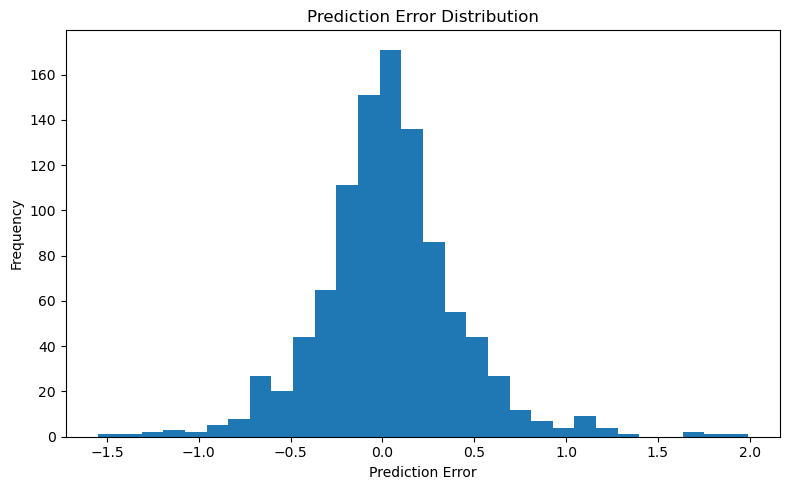

In [103]:
#Error distrubution
plt.figure(figsize=(8, 5))

plt.hist(
    error_df["Error"],
    bins=30
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title("Prediction Error Distribution")

plt.tight_layout()

plt.show()

In [104]:
import pickle

In [105]:
best_model

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [106]:
model_path = "../models/mental_health.pkl"
with open(model_path , 'wb') as file:
    pickle.dump(best_model , file)


print("model saved successfully")   

model saved successfully
